In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [29]:
from google.colab import files
uploaded =files.upload()
csv_file=next(iter(uploaded))
df = pd.read_csv(csv_file)
print("Success")

Saving test-data.csv to test-data (2).csv
Success


In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1234 entries, 0 to 1233
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         1234 non-null   int64  
 1   Name               1234 non-null   object 
 2   Location           1234 non-null   object 
 3   Year               1234 non-null   int64  
 4   Kilometers_Driven  1234 non-null   int64  
 5   Fuel_Type          1234 non-null   object 
 6   Transmission       1234 non-null   object 
 7   Owner_Type         1234 non-null   object 
 8   Mileage            1234 non-null   object 
 9   Engine             1224 non-null   object 
 10  Power              1224 non-null   object 
 11  Seats              1223 non-null   float64
 12  New_Price          182 non-null    object 
dtypes: float64(1), int64(3), object(9)
memory usage: 125.5+ KB


In [31]:
df.head()


,Unnamed: 0,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price
0,0,Maruti Alto K10 LXI CNG,Delhi,2014,40929,CNG,Manual,First,32.26 km/kg,998 CC,58.2 bhp,4.0,NaN
1,1,Maruti Alto 800 2016-2019 LXI,Coimbatore,2013,54493,Petrol,Manual,Second,24.7 kmpl,796 CC,47.3 bhp,5.0,NaN
2,2,Toyota Innova Crysta Touring Sport 2.4 MT,Mumbai,2017,34000,Diesel,Manual,First,13.68 kmpl,2393 CC,147.8 bhp,7.0,25.27 Lakh
3,3,Toyota Etios Liva GD,Hyderabad,2012,139000,Diesel,Manual,First,23.59 kmpl,1364 CC,null bhp,5.0,NaN
4,4,Hyundai i20 Magna,Mumbai,2014,29000,Petrol,Manual,First,18.5 kmpl,1197 CC,82.85 bhp,5.0,NaN


In [32]:
display(df.head())

,Unnamed: 0,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price
0,0,Maruti Alto K10 LXI CNG,Delhi,2014,40929,CNG,Manual,First,32.26 km/kg,998 CC,58.2 bhp,4.0,NaN
1,1,Maruti Alto 800 2016-2019 LXI,Coimbatore,2013,54493,Petrol,Manual,Second,24.7 kmpl,796 CC,47.3 bhp,5.0,NaN
2,2,Toyota Innova Crysta Touring Sport 2.4 MT,Mumbai,2017,34000,Diesel,Manual,First,13.68 kmpl,2393 CC,147.8 bhp,7.0,25.27 Lakh
3,3,Toyota Etios Liva GD,Hyderabad,2012,139000,Diesel,Manual,First,23.59 kmpl,1364 CC,null bhp,5.0,NaN
4,4,Hyundai i20 Magna,Mumbai,2014,29000,Petrol,Manual,First,18.5 kmpl,1197 CC,82.85 bhp,5.0,NaN


In [33]:
df.tail()


,Unnamed: 0,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price
1229,1229,Volkswagen Vento Diesel Trendline,Hyderabad,2011,89411,Diesel,Manual,First,20.54 kmpl,1598 CC,103.6 bhp,5.0,NaN
1230,1230,Volkswagen Polo GT TSI,Mumbai,2015,59000,Petrol,Automatic,First,17.21 kmpl,1197 CC,103.6 bhp,5.0,NaN
1231,1231,Nissan Micra Diesel XV,Kolkata,2012,28000,Diesel,Manual,First,23.08 kmpl,1461 CC,63.1 bhp,5.0,NaN
1232,1232,Volkswagen Polo GT TSI,Pune,2013,52262,Petrol,Automatic,Third,17.2 kmpl,1197 CC,103.6 bhp,5.0,NaN
1233,1233,Mercedes-Benz E-Class 2009-2013 E 220 CDI Avan...,Kochi,2014,72443,Diesel,Automatic,First,10.0 kmpl,2148 CC,170 bhp,5.0,NaN


In [34]:
df.duplicated().sum()

np.int64(0)

In [35]:
df.isnull().sum()

,0
Unnamed: 0,0
Name,0
Location,0
Year,0
Kilometers_Driven,0
Fuel_Type,0
Transmission,0
Owner_Type,0
Mileage,0
Engine,10


In [36]:
df = df.drop(columns=['Unnamed: 0'])
df.columns.tolist()

['Name',
 'Location',
 'Year',
 'Kilometers_Driven',
 'Fuel_Type',
 'Transmission',
 'Owner_Type',
 'Mileage',
 'Engine',
 'Power',
 'Seats',
 'New_Price']

In [37]:
print(df[['Mileage', 'Engine', 'Power', 'New_Price']].head(10))

       Mileage   Engine      Power   New_Price
0  32.26 km/kg   998 CC   58.2 bhp         NaN
1    24.7 kmpl   796 CC   47.3 bhp         NaN
2   13.68 kmpl  2393 CC  147.8 bhp  25.27 Lakh
3   23.59 kmpl  1364 CC   null bhp         NaN
4    18.5 kmpl  1197 CC  82.85 bhp         NaN
5    16.0 kmpl  2179 CC    140 bhp         NaN
6   12.55 kmpl  2982 CC  168.7 bhp         NaN
7    21.1 kmpl   814 CC   55.2 bhp         NaN
8    17.0 kmpl  1497 CC    118 bhp         NaN
9    15.1 kmpl  2179 CC    140 bhp         NaN


In [39]:
# Converting measurement data to numerical
df['Mileage'] = df['Mileage'].astype(str).str.extract(r'(\d+\.?\d*)')[0].astype(float)
df['Engine'] = df['Engine'].astype(str).str.extract(r'(\d+\.?\d*)')[0].astype(float)
df['Power'] = df['Power'].astype(str).str.extract(r'(\d+\.?\d*)')[0].astype(float)
df[['Mileage', 'Engine', 'Power']].head()

,Mileage,Engine,Power
0,32.26,998.0,58.20
1,24.70,796.0,47.30
2,13.68,2393.0,147.80
3,23.59,1364.0,NaN
4,18.50,1197.0,82.85


In [40]:
# Checking missing values
df.isnull().sum()

,0
Name,0
Location,0
Year,0
Kilometers_Driven,0
Fuel_Type,0
Transmission,0
Owner_Type,0
Mileage,0
Engine,10
Power,32


In [41]:
# Handling missing numerical values
num = df.select_dtypes(include=['number']).columns
df[num] = df[num].fillna(df[num].median())
df.isnull().sum()

,0
Name,0
Location,0
Year,0
Kilometers_Driven,0
Fuel_Type,0
Transmission,0
Owner_Type,0
Mileage,0
Engine,0
Power,0


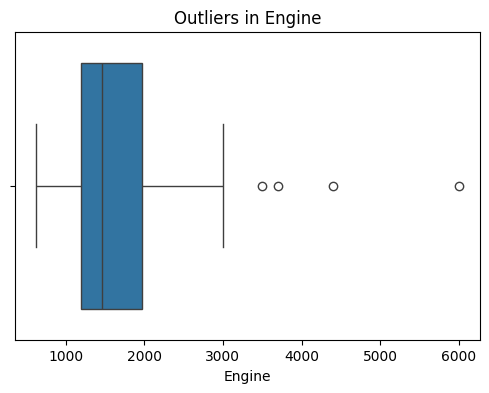

In [42]:
# Outlier check
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(6, 4))
sns.boxplot(x=df['Engine'])
plt.title('Outliers in Engine')
plt.show()

In [43]:
# Calculating IQR
Q1 = df['Engine'].quantile(0.25)
Q3 = df['Engine'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Lower bound: 43.0
Upper bound: 3123.0


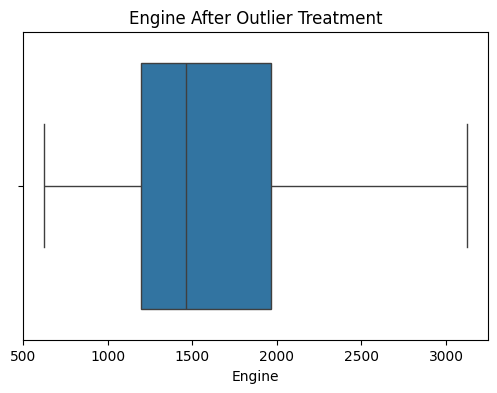

In [44]:
# Handling outliers
df['Engine'] = df['Engine'].clip(lower_bound, upper_bound)
# Check outliers again
plt.figure(figsize=(6, 4))
sns.boxplot(x=df['Engine'])
plt.title('Engine After Outlier Treatment')
plt.show()

In [45]:
# Converting objective data to numerical
df_encoded = df.copy()
df1 = df_encoded.select_dtypes(include='object').columns
df1

Index(['Name', 'Location', 'Fuel_Type', 'Transmission', 'Owner_Type',
       'New_Price'],
      dtype='object')

In [46]:
# Label Encoding
from sklearn.preprocessing import LabelEncoder
for col in df1:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col].fillna('Missing').astype(str))
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1234 entries, 0 to 1233
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               1234 non-null   int64  
 1   Location           1234 non-null   int64  
 2   Year               1234 non-null   int64  
 3   Kilometers_Driven  1234 non-null   int64  
 4   Fuel_Type          1234 non-null   int64  
 5   Transmission       1234 non-null   int64  
 6   Owner_Type         1234 non-null   int64  
 7   Mileage            1234 non-null   float64
 8   Engine             1234 non-null   float64
 9   Power              1234 non-null   float64
 10  Seats              1234 non-null   float64
 11  New_Price          1234 non-null   int64  
dtypes: float64(4), int64(8)
memory usage: 115.8 KB


In [47]:
df_encoded.head()

,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price
0,413,4,2014,40929,0,1,0,32.26,998.0,58.20,4.0,162
1,408,3,2013,54493,3,1,2,24.70,796.0,47.30,5.0,162
2,723,9,2017,34000,1,1,0,13.68,2393.0,147.80,7.0,54
3,689,5,2012,139000,1,1,0,23.59,1364.0,93.70,5.0,162
4,333,9,2014,29000,3,1,0,18.50,1197.0,82.85,5.0,162


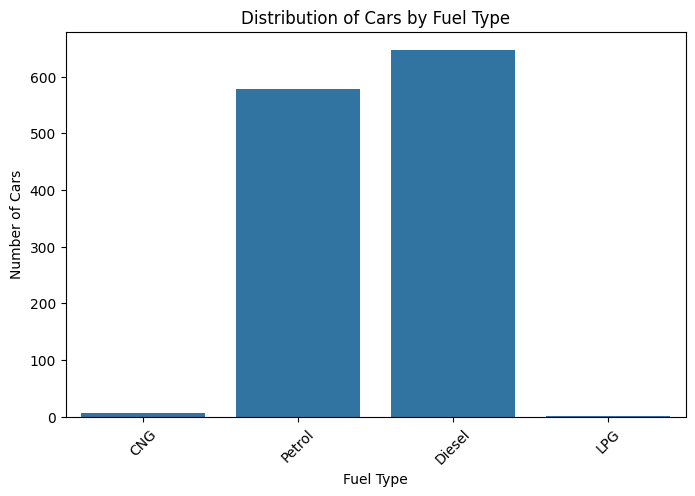

In [48]:
# Univariate analysis
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 5))
sns.countplot(x='Fuel_Type', data=df)
plt.title('Distribution of Cars by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Number of Cars')
plt.xticks(rotation=45)
plt.show()


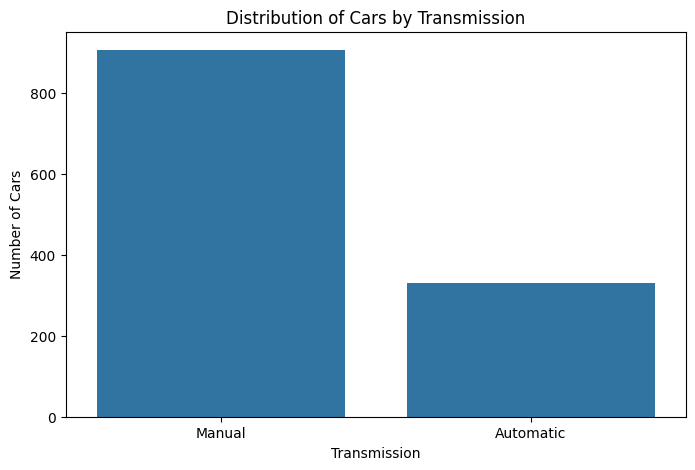

In [49]:
plt.figure(figsize=(8, 5))
sns.countplot(x='Transmission', data=df)
plt.title('Distribution of Cars by Transmission')
plt.xlabel('Transmission')
plt.ylabel('Number of Cars')
plt.show()


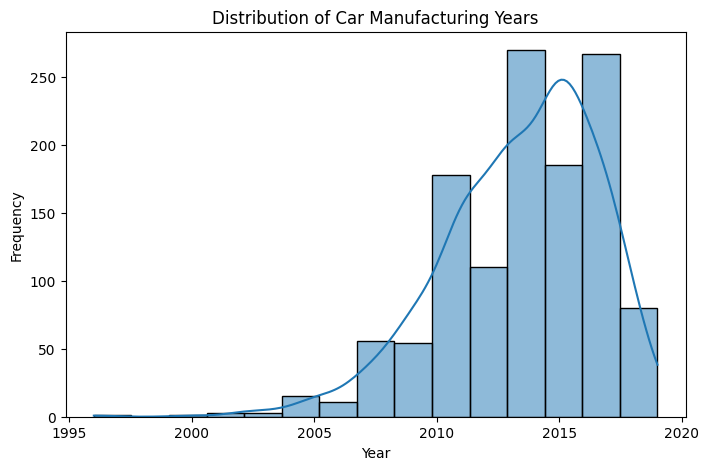

In [50]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Year', bins=15, kde=True)
plt.title('Distribution of Car Manufacturing Years')
plt.xlabel('Year')
plt.ylabel('Frequency')
plt.show()


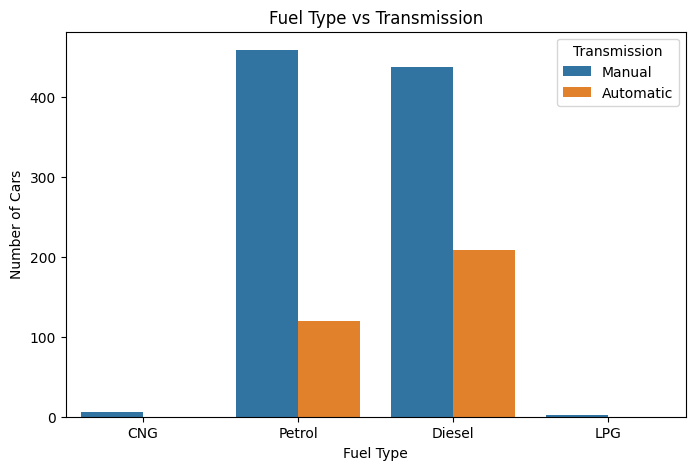

In [51]:
# Bivariate analysis
plt.figure(figsize=(8, 5))
sns.countplot(x='Fuel_Type', hue='Transmission', data=df)
plt.title('Fuel Type vs Transmission')
plt.xlabel('Fuel Type')
plt.ylabel('Number of Cars')
plt.legend(title='Transmission')
plt.show()

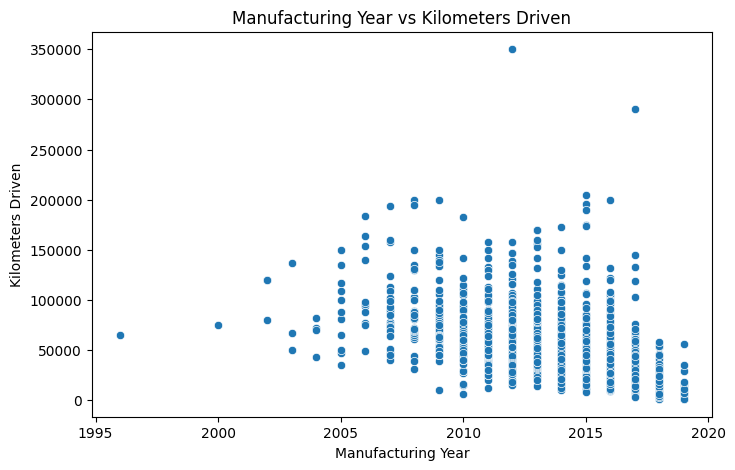

In [52]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Year',y='Kilometers_Driven',data=df)
plt.title('Manufacturing Year vs Kilometers Driven')
plt.xlabel('Manufacturing Year')
plt.ylabel('Kilometers Driven')
plt.show()

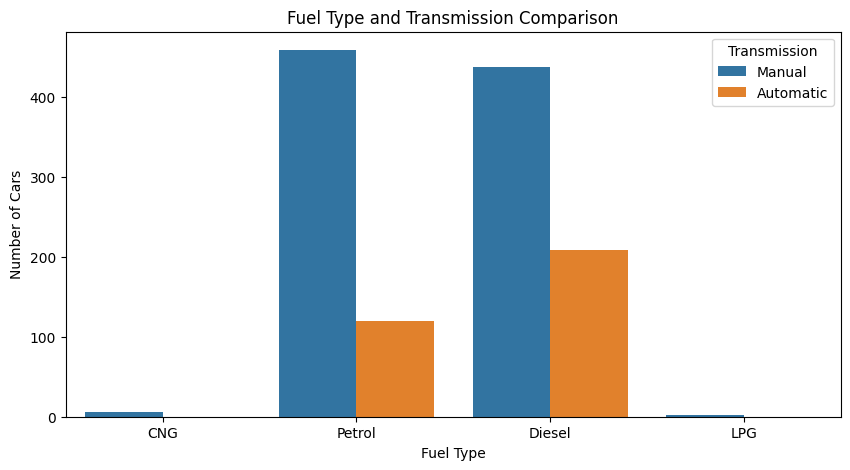

In [53]:
# Multivariate analysis
plt.figure(figsize=(10, 5))
sns.countplot(x='Fuel_Type',hue='Transmission',data=df)
plt.title('Fuel Type and Transmission Comparison')
plt.xlabel('Fuel Type')
plt.ylabel('Number of Cars')
plt.legend(title='Transmission')
plt.show()

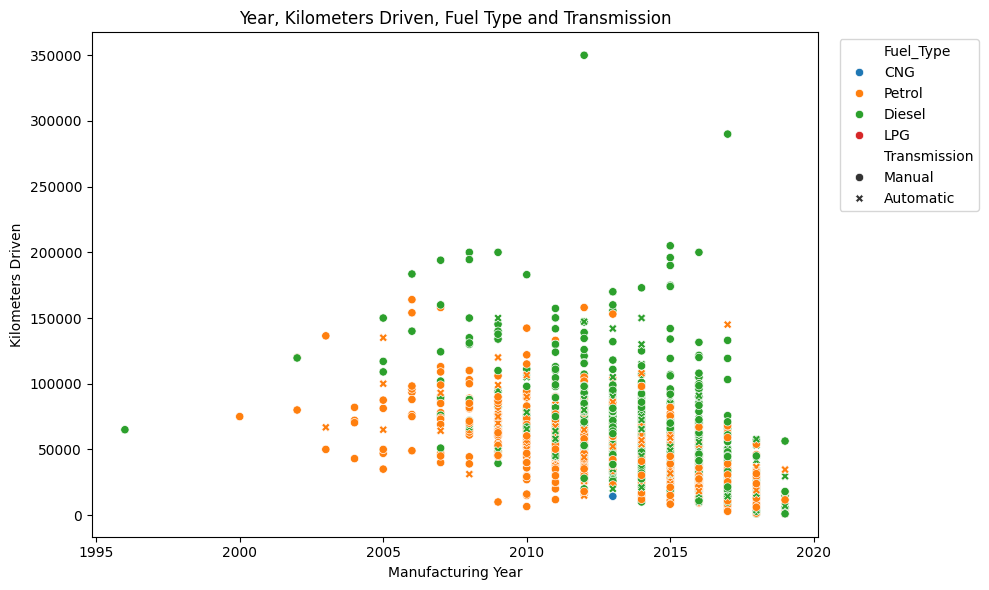

In [54]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df,x='Year',y='Kilometers_Driven',hue='Fuel_Type',style='Transmission')
plt.title('Year, Kilometers Driven, Fuel Type and Transmission')
plt.xlabel('Manufacturing Year')
plt.ylabel('Kilometers Driven')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()